<div style="background-color:#1E1B4B; background-image:linear-gradient(135deg, #0F172A 0%, #312E81 100%); color:#FFFFFF; border-radius:16px; padding:34px 38px;">
<div style="font-size:12px; letter-spacing:3px; color:#A5B4FC; font-weight:700;">IMPERIAL COLLEGE LONDON &nbsp;·&nbsp; ELEC70144 &nbsp;·&nbsp; <span style="white-space:nowrap;">2026–2027</span></div>
<div style="font-size:15px; color:#CBD5E1; margin-top:6px;">Mathematics for Machine Learning</div>
<div style="font-size:13px; color:#A5B4FC; margin-top:22px; font-weight:700; letter-spacing:2px;">TUTORIAL 01</div>
<div style="font-size:32px; font-weight:800; line-height:1.2; color:#FFFFFF; margin-top:2px;">Matrices, Transposes &amp; Linear Independence</div>
<div style="font-size:15px; color:#CBD5E1; margin-top:12px; max-width:720px; line-height:1.5;">From rotating images to the dummy-variable trap: why the structure of a matrix decides whether a model can be learned at all.</div>
<div style="margin-top:22px;">
<span style="display:inline-block; white-space:nowrap; margin:0 4px 8px 0; background-color:#1E293B; border:1px solid #334155; color:#E2E8F0; padding:5px 12px; border-radius:999px; font-size:12px; font-weight:600;"><span style="color:#818CF8;">●</span>&nbsp; NumPy · Matplotlib · pandas</span>&nbsp;
<span style="display:inline-block; white-space:nowrap; margin:0 4px 8px 0; background-color:#1E293B; border:1px solid #334155; color:#E2E8F0; padding:5px 12px; border-radius:999px; font-size:12px; font-weight:600;"><span style="color:#2DD4BF;">●</span>&nbsp; Linear algebra</span>&nbsp;
<span style="display:inline-block; white-space:nowrap; margin:0 4px 8px 0; background-color:#1E293B; border:1px solid #334155; color:#E2E8F0; padding:5px 12px; border-radius:999px; font-size:12px; font-weight:600;"><span style="color:#A78BFA;">●</span>&nbsp; ML connections</span>&nbsp;
<span style="display:inline-block; white-space:nowrap; margin:0 4px 8px 0; background-color:#1E293B; border:1px solid #334155; color:#E2E8F0; padding:5px 12px; border-radius:999px; font-size:12px; font-weight:600;"><span style="color:#FBBF24;">●</span>&nbsp; 3 exercises</span>
</div>
</div>

<div style="background-color:#F8FAFC; border:1px solid #E2E8F0; border-left:4px solid #4F46E5; border-radius:10px; color:#1E293B; padding:14px 20px; margin:14px 0;">

<span style="background-color:#EEF2FF; color:#3730A3; font-size:11px; font-weight:700; letter-spacing:1.5px; padding:3px 10px; border-radius:999px;">OBJECTIVES</span>&nbsp;&nbsp;<b style="color:#0F172A; font-size:15px;">Learning objectives</b>

By the end of this tutorial you should be able to:

1. **Transpose** a matrix, and use transposes to **rotate images**.
2. Explain what it means for vectors to be **linearly independent**, and check it with the **rank**.
3. Explain why **dependent features** break a linear regression model (the **dummy-variable trap**).
4. Use the **determinant** and **condition number** to tell how close a matrix is to "broken".

</div>

### Roadmap

| | Section | The one idea to take away |
|:-:|:--|:--|
| **1** | [Transposing & rotating images](#sec1) | The transpose swaps rows and columns |
| **2** | [Linear independence](#sec2) | Independent vectors each add a new direction |
| **3** | [Rank](#sec3) | Rank counts the independent columns |
| **4** | [Why dependence hurts in ML](#sec4) | Dependent features mean the model has no unique answer |
| **5** | [The determinant](#sec5) | det = 0 means the matrix flattens space |
| **6** | [Linear regression with matrices](#sec6) | A unique best-fit line needs independent columns |
| **7** | [Summary](#sec7) | A checklist for your feature matrix |

Run the cells **in order**. Each section follows the same pattern: **idea → small example → picture → what it tells us**.
<span style="color:#D97706;">**Exercises**</span> come with hidden solutions. Try them yourself first.

### Setup
Run these cells first. It loads the libraries, picks the colours, and defines three small helper functions used throughout: `show_matrix` (draw a matrix with its numbers), `show_image` (draw a matrix as a picture) and `draw_vectors` (draw arrows). You don't need to read how they work to follow the tutorial.

In [ ]:
# If you need to install the libraries, uncomment the following lines:
# !pip install numpy
# !pip install pandas
# !pip install matplotlib

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Colours used in the plots
BLUE       = "#4F46E5"
LIGHT_BLUE = "#C7D2FE"
ORANGE     = "#F59E0B"
RED        = "#F43F5E"
TEAL       = "#14B8A6"
GREY       = "#64748B"
DARK       = "#0F172A"

# Plot style: makes every figure look the same (no need to read this part)
plt.rcParams.update({
    "figure.dpi": 110, "figure.autolayout": True, "lines.linewidth": 2.5,
    "axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": "#CBD5E1",
    "axes.titleweight": "bold", "axes.titlesize": 12, "axes.titlelocation": "left",
    "axes.labelcolor": "#334155", "text.color": DARK, "xtick.color": GREY, "ytick.color": GREY,
    "grid.color": "#E2E8F0", "axes.axisbelow": True, "legend.frameon": False,
})
np.set_printoptions(precision=4, suppress=True)   # print numbers neatly


def show_matrix(ax, matrix, title):
    """Draw a matrix as a coloured grid, with each number written in its cell."""
    ax.imshow(matrix, cmap="viridis")
    middle = (matrix.min() + matrix.max()) / 2
    for i in range(matrix.shape[0]):          # each row
        for j in range(matrix.shape[1]):      # each column
            value = matrix[i, j]
            text_colour = "white" if value < middle else "black"   # dark cells get white text
            ax.text(j, i, value, ha="center", va="center", fontsize=11, fontweight="bold", color=text_colour)
    ax.set_title(f"{title}\nshape {matrix.shape[0]}×{matrix.shape[1]}")
    ax.set_xticks(range(matrix.shape[1]))     # label columns 0, 1, 2, ...
    ax.set_yticks(range(matrix.shape[0]))     # label rows 0, 1, 2, ...
    ax.set_xlabel("column")
    ax.set_ylabel("row")


def show_image(ax, image, title, cmap="viridis"):
    """Draw a matrix as a picture, without axis ticks."""
    ax.imshow(image, cmap=cmap)
    ax.set_title(title, fontsize=11)
    ax.axis("off")


def draw_vectors(ax, vectors, labels, colours):
    """Draw 2-D vectors as arrows starting at the origin (0, 0)."""
    for vector, label, colour in zip(vectors, labels, colours):
        ax.quiver(0, 0, vector[0], vector[1], angles="xy", scale_units="xy", scale=1,
                  color=colour, width=0.015, label=label)
    ax.axhline(0, color=GREY, linewidth=0.8)   # x-axis
    ax.axvline(0, color=GREY, linewidth=0.8)   # y-axis
    ax.set_aspect("equal")
    ax.grid(True)
    ax.legend(loc="upper left")

print("✅ Setup complete")

✅ Setup complete


<a id="sec1"></a>

<div style="margin-top:28px; font-size:12px; font-weight:700; letter-spacing:3px; color:#4F46E5;">SECTION 01</div>

## Transposing & Rotating Images

<div style="color:#64748B; font-size:15px;">A greyscale image is just a matrix of numbers, so editing an image is doing maths on a matrix.</div>

<hr style="border:none; height:4px; width:56px; background-color:#4F46E5; border-radius:2px; margin:12px 0 6px 0;">

<div style="background-color:#F8FAFC; border:1px solid #E2E8F0; border-left:4px solid #4F46E5; border-radius:10px; color:#1E293B; padding:14px 20px; margin:14px 0;">

<span style="background-color:#EEF2FF; color:#3730A3; font-size:11px; font-weight:700; letter-spacing:1.5px; padding:3px 10px; border-radius:999px;">DEFINITION</span>&nbsp;&nbsp;<b style="color:#0F172A; font-size:15px;">The transpose</b>

The **transpose** $A^\top$ of a matrix $A$ turns its rows into columns:

$$
(A^\top)_{ij} = A_{ji}.
$$

An $m \times n$ matrix becomes $n \times m$. In pictures, the matrix is **mirrored across its main diagonal** (top-left to bottom-right).

</div>

### Example 1.1: Transposing a tiny image
Here is a $3 \times 4$ "image": each number is the brightness of one pixel. The dashed line is the main diagonal, which acts as the mirror.

Shape of image:      (3, 4)
Shape of transposed: (4, 3)


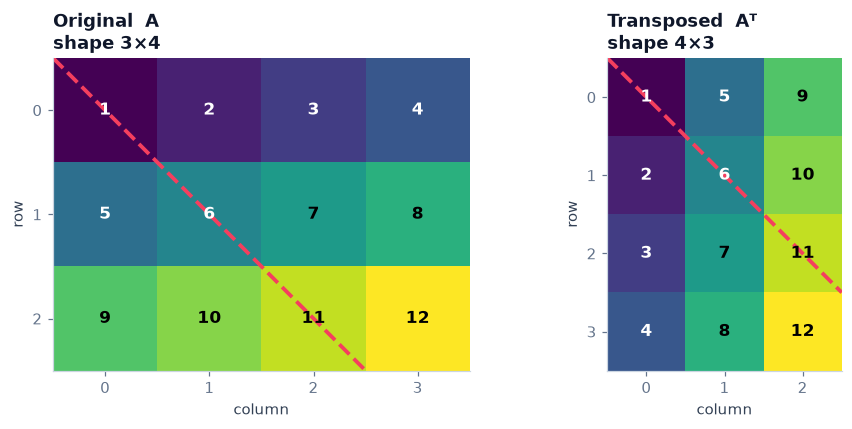

In [4]:
image = np.array([[1,  2,  3,  4],
                  [5,  6,  7,  8],
                  [9, 10, 11, 12]])
transposed = image.T

print("Shape of image:     ", image.shape)
print("Shape of transposed:", transposed.shape)

# Draw both matrices side by side
fig, axes = plt.subplots(1, 2, figsize=(9, 4))
show_matrix(axes[0], image, "Original  A")
show_matrix(axes[1], transposed, "Transposed  Aᵀ")

# Draw the main diagonal (the "mirror") as a dashed red line on both
axes[0].plot([-0.5, 2.5], [-0.5, 2.5], "--", color=RED)
axes[1].plot([-0.5, 2.5], [-0.5, 2.5], "--", color=RED)
plt.show()

<div style="background-color:#F8FAFC; border:1px solid #E2E8F0; border-left:4px solid #0D9488; border-radius:10px; color:#1E293B; padding:14px 20px; margin:14px 0;">

<span style="background-color:#CCFBF1; color:#115E59; font-size:11px; font-weight:700; letter-spacing:1.5px; padding:3px 10px; border-radius:999px;">INTUITION</span>&nbsp;&nbsp;<b style="color:#0F172A; font-size:15px;">What to notice</b>

- The **first row** of $A$ (`1 2 3 4`) has become the **first column** of $A^\top$.
- The numbers **on the diagonal** (`1`, `6`, `11`) stay where they are.
- The shape changes from $3\times4$ to $4\times3$.

</div>

### Example 1.2: Rotation = transpose + flip
On its own, the transpose **mirrors** an image. Add one **flip** and you get a **rotation**:

| To rotate by… | NumPy shortcut | Same thing, built from a transpose |
|:--|:--|:--|
| 90° anticlockwise | `np.rot90(A)` | `np.flipud(A.T)` (transpose, then flip upside-down) |
| 90° clockwise | `np.rot90(A, -1)` | `np.fliplr(A.T)` (transpose, then flip left-right) |

We use the letter **F** because it looks different from every side, so you can see exactly what each operation does.

Matches np.rot90(F):     True
Matches np.rot90(F, -1): True


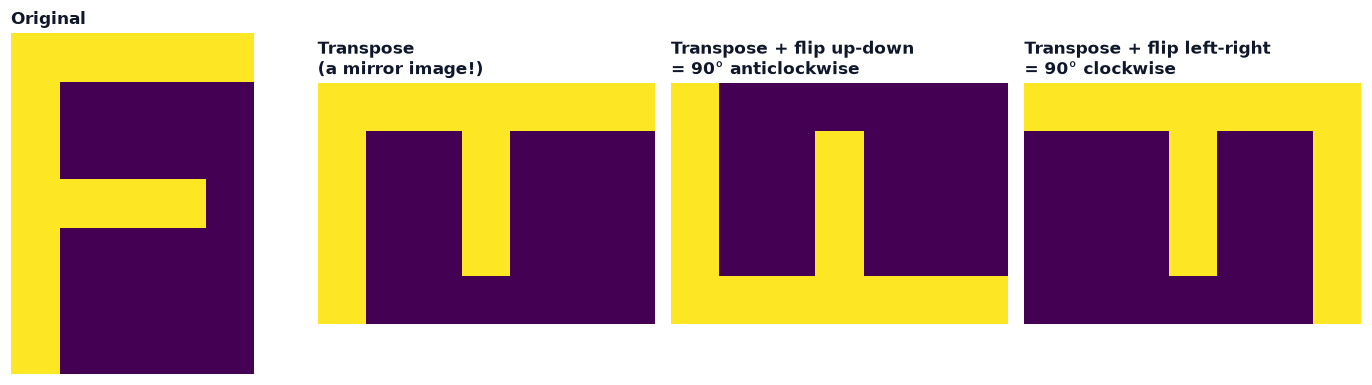

In [5]:
F = np.array([[1, 1, 1, 1, 1],
              [1, 0, 0, 0, 0],
              [1, 0, 0, 0, 0],
              [1, 1, 1, 1, 0],
              [1, 0, 0, 0, 0],
              [1, 0, 0, 0, 0],
              [1, 0, 0, 0, 0]])

# Rotate by hand: transpose, then flip
anticlockwise = np.flipud(F.T)   # flipud = flip upside-down
clockwise = np.fliplr(F.T)       # fliplr = flip left-right

# Check against NumPy's built-in rotation function (both should print True)
print("Matches np.rot90(F):    ", np.array_equal(anticlockwise, np.rot90(F)))
print("Matches np.rot90(F, -1):", np.array_equal(clockwise, np.rot90(F, -1)))

fig, axes = plt.subplots(1, 4, figsize=(13, 3.6))
show_image(axes[0], F, "Original")
show_image(axes[1], F.T, "Transpose\n(a mirror image!)")
show_image(axes[2], anticlockwise, "Transpose + flip up-down\n= 90° anticlockwise")
show_image(axes[3], clockwise, "Transpose + flip left-right\n= 90° clockwise")
plt.show()

<div style="background-color:#F8FAFC; border:1px solid #E2E8F0; border-left:4px solid #7C3AED; border-radius:10px; color:#1E293B; padding:14px 20px; margin:14px 0;">

<span style="background-color:#EDE9FE; color:#5B21B6; font-size:11px; font-weight:700; letter-spacing:1.5px; padding:3px 10px; border-radius:999px;">ML CONNECTION</span>&nbsp;&nbsp;<b style="color:#0F172A; font-size:15px;">Why transposes are everywhere in ML</b>

In machine learning, a dataset is stored as a **data matrix** $X$ with **one row per sample** (e.g. per house) and **one column per feature** (e.g. size, age). With $N$ samples and $D$ features, $X \in \mathbb{R}^{N \times D}$. The transpose lets us switch between thinking about samples and thinking about features:

| Expression | Shape | What it means |
|:--|:--|:--|
| $\boldsymbol\theta^\top \mathbf x$ | a number | A linear model's prediction for one sample $\mathbf x$, using weights $\boldsymbol\theta$. |
| $X\boldsymbol\theta$ | $N$ | The predictions for all $N$ samples at once. |
| $X^\top X$ | $D \times D$ | How the features relate to each other. |
| $X^\top(X\boldsymbol\theta - \mathbf y)$ | $D$ | The gradient used to train a linear model. The transpose sends each sample's error back to the weights. |

Tip: many NumPy shape errors are fixed by a missing `.T`. Writing down the shape of each term is the quickest way to find the problem.

</div>

<div style="background-color:#F8FAFC; border:1px solid #E2E8F0; border-left:4px solid #D97706; border-radius:10px; color:#1E293B; padding:14px 20px; margin:14px 0;">

<span style="background-color:#FEF3C7; color:#92400E; font-size:11px; font-weight:700; letter-spacing:1.5px; padding:3px 10px; border-radius:999px;">EXERCISE</span>&nbsp;&nbsp;<b style="color:#0F172A; font-size:15px;">Exercise 1</b>

**(a)** Using only `.T`, `np.flipud` and `np.fliplr`, rotate `F` by **180°**. Check your answer with `np.rot90(F, 2)`.

**(b)** Is the transpose of an image ever the same as a rotation of it? Use the **F** to explain.

<details>
<summary><b>Show solution ▸</b></summary>

**(a)** Rotating 180° is the same as flipping both up-down and left-right:

```python
rot180 = np.flipud(np.fliplr(F))
np.array_equal(rot180, np.rot90(F, 2))   # True
```

**(b)** No. The transpose turns the **F** into a mirror image (it faces backwards), and no rotation can do that.

</details>

</div>

In [6]:
# ✏️ Exercise 1: your code here

<a id="sec2"></a>

<div style="margin-top:28px; font-size:12px; font-weight:700; letter-spacing:3px; color:#4F46E5;">SECTION 02</div>

## Linear Independence

<div style="color:#64748B; font-size:15px;">Does each vector bring something new, or can it be built from the others?</div>

<hr style="border:none; height:4px; width:56px; background-color:#4F46E5; border-radius:2px; margin:12px 0 6px 0;">

<div style="background-color:#F8FAFC; border:1px solid #E2E8F0; border-left:4px solid #4F46E5; border-radius:10px; color:#1E293B; padding:14px 20px; margin:14px 0;">

<span style="background-color:#EEF2FF; color:#3730A3; font-size:11px; font-weight:700; letter-spacing:1.5px; padding:3px 10px; border-radius:999px;">DEFINITION</span>&nbsp;&nbsp;<b style="color:#0F172A; font-size:15px;">Linear independence</b>

In words: a set of vectors is **linearly independent** if **none of them can be built from the others** by scaling and adding. If one can, the set is **linearly dependent** and that vector is *redundant*.

For **two vectors** this is easy to check: they are dependent exactly when one is a multiple of the other ($\mathbf v_2 = c\,\mathbf v_1$).

<details>
<summary><b>The formal definition ▸</b></summary>

$\mathbf v_1, \dots, \mathbf v_k$ are linearly independent if the only way to get the zero vector,
$c_1\mathbf v_1 + \dots + c_k\mathbf v_k = \mathbf 0$, is to choose every $c_i = 0$.

</details>

</div>

### Example 2.1: Two pairs of vectors
- $\mathbf v_1 = (1, 0)$ and $\mathbf v_2 = (0, 1)$ point in different directions, so they are **independent**.
- $\mathbf v_3 = (1, 2)$ and $\mathbf v_4 = (2, 4)$. Since $\mathbf v_4 = 2\,\mathbf v_3$, they are **dependent**.

Is v4 equal to 2 * v3? True


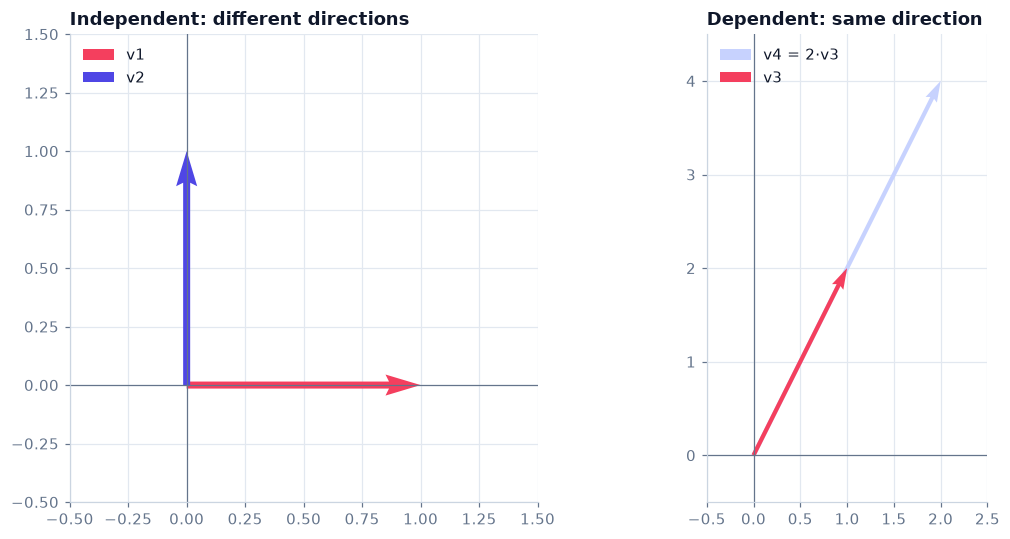

In [7]:
v1 = np.array([1, 0])
v2 = np.array([0, 1])
v3 = np.array([1, 2])
v4 = np.array([2, 4])

print("Is v4 equal to 2 * v3?", np.array_equal(v4, 2 * v3))

fig, axes = plt.subplots(1, 2, figsize=(11, 5))

draw_vectors(axes[0], [v1, v2], ["v1", "v2"], [RED, BLUE])
axes[0].set_xlim(-0.5, 1.5)
axes[0].set_ylim(-0.5, 1.5)
axes[0].set_title("Independent: different directions")

draw_vectors(axes[1], [v4, v3], ["v4 = 2·v3", "v3"], [LIGHT_BLUE, RED])   # draw v4 first so v3 is on top
axes[1].set_xlim(-0.5, 2.5)
axes[1].set_ylim(-0.5, 4.5)
axes[1].set_title("Dependent: same direction")
plt.show()

### Example 2.2: Where can the vectors take us?
Think of each vector as a direction you are allowed to move in, as far as you like, forwards or backwards. The set of all points you can reach by combining them is called their **span**.

To see it, we pick 3000 random pairs of numbers $(c_1, c_2)$, compute $c_1\mathbf v_1 + c_2\mathbf v_2$ for each pair, and plot where it lands. Then we do the same with $\mathbf v_3$ and $\mathbf v_4$.

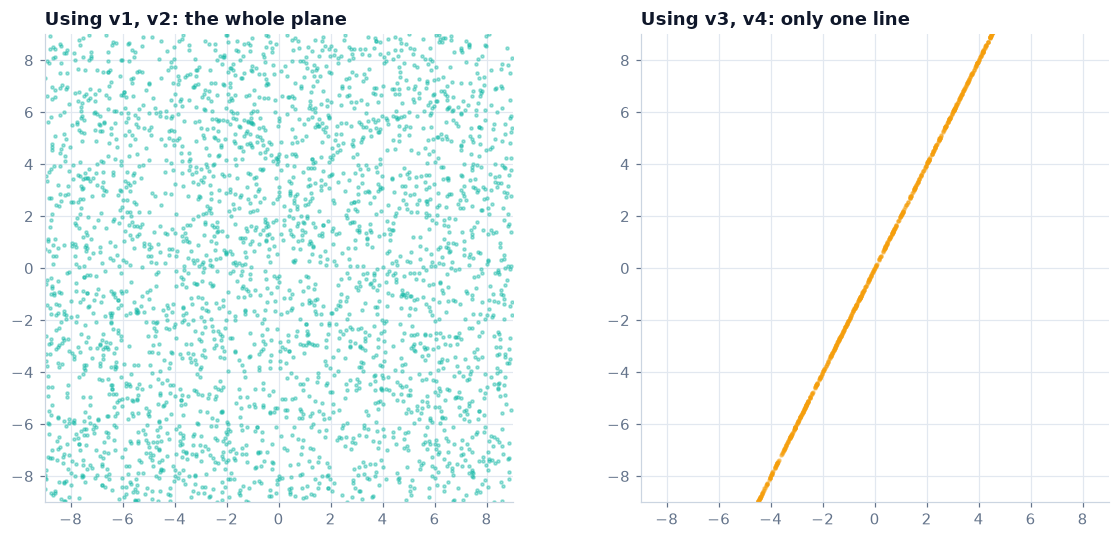

In [8]:
rng = np.random.default_rng(0)        # random number generator (seed 0: same numbers every run)
c1 = rng.uniform(-9, 9, 3000)         # 3000 random numbers between -9 and 9
c2 = rng.uniform(-9, 9, 3000)         # 3000 more

# For every pair (c1, c2), work out the point c1 * v1 + c2 * v2
points_independent = np.column_stack([c1 * v1[0] + c2 * v2[0],     # x-coordinates
                                      c1 * v1[1] + c2 * v2[1]])    # y-coordinates

# Same again with the dependent vectors: c1 * v3 + c2 * v4
points_dependent = np.column_stack([c1 * v3[0] + c2 * v4[0],
                                    c1 * v3[1] + c2 * v4[1]])

fig, axes = plt.subplots(1, 2, figsize=(11, 5))
axes[0].scatter(points_independent[:, 0], points_independent[:, 1], s=4, alpha=0.4, color=TEAL)
axes[0].set_title("Using v1, v2: the whole plane")
axes[1].scatter(points_dependent[:, 0], points_dependent[:, 1], s=4, alpha=0.4, color=ORANGE)
axes[1].set_title("Using v3, v4: only one line")

for ax in axes:                       # same zoom on both plots
    ax.set_xlim(-9, 9)
    ax.set_ylim(-9, 9)
    ax.set_aspect("equal")
    ax.grid(True)
plt.show()

<div style="background-color:#F8FAFC; border:1px solid #E2E8F0; border-left:4px solid #0D9488; border-radius:10px; color:#1E293B; padding:14px 20px; margin:14px 0;">

<span style="background-color:#CCFBF1; color:#115E59; font-size:11px; font-weight:700; letter-spacing:1.5px; padding:3px 10px; border-radius:999px;">INTUITION</span>&nbsp;&nbsp;<b style="color:#0F172A; font-size:15px;">What this tells us</b>

Two **independent** vectors can reach **every point** of the plane. Two **dependent** vectors are stuck on **one line**: the second vector adds nothing new.

The same is true for data. If one feature can be built from the others, it carries **no new information**.

</div>

<a id="sec3"></a>

<div style="margin-top:28px; font-size:12px; font-weight:700; letter-spacing:3px; color:#4F46E5;">SECTION 03</div>

## Rank: Counting Independent Columns

<div style="color:#64748B; font-size:15px;">One number that tells us whether a matrix has redundant columns.</div>

<hr style="border:none; height:4px; width:56px; background-color:#4F46E5; border-radius:2px; margin:12px 0 6px 0;">

<div style="background-color:#F8FAFC; border:1px solid #E2E8F0; border-left:4px solid #4F46E5; border-radius:10px; color:#1E293B; padding:14px 20px; margin:14px 0;">

<span style="background-color:#EEF2FF; color:#3730A3; font-size:11px; font-weight:700; letter-spacing:1.5px; padding:3px 10px; border-radius:999px;">DEFINITION</span>&nbsp;&nbsp;<b style="color:#0F172A; font-size:15px;">Rank</b>

Put the vectors in the **columns** of a matrix $A$. The **rank** of $A$ is the number of independent columns.

- rank $=$ number of columns: all columns are independent (**full rank**).
- rank $<$ number of columns: some columns are redundant.

NumPy computes it with `np.linalg.matrix_rank(A)`.

</div>

In [9]:
examples = {
    "[[1, 0], [0, 1]]":                    np.array([[1, 0], [0, 1]]),
    "[[1, 2], [2, 4]]  (col 2 = 2·col 1)": np.array([[1, 2], [2, 4]]),
    "4×3, independent columns":            np.array([[1, 0, 2], [0, 1, 3], [2, 1, 0], [1, 2, 1]]),
    "4×3, col 3 = 2·col 1 + col 2":        np.array([[1, 0, 2], [0, 1, 1], [2, 1, 5], [1, 2, 4]]),
}

for name, matrix in examples.items():
    rank = np.linalg.matrix_rank(matrix)
    num_columns = matrix.shape[1]

    if rank == num_columns:
        verdict = "✅ independent"
    else:
        verdict = "❌ dependent"

    print(name)
    print(f"    rank {rank} of {num_columns} columns  →  {verdict}")

[[1, 0], [0, 1]]
    rank 2 of 2 columns  →  ✅ independent
[[1, 2], [2, 4]]  (col 2 = 2·col 1)
    rank 1 of 2 columns  →  ❌ dependent
4×3, independent columns
    rank 3 of 3 columns  →  ✅ independent
4×3, col 3 = 2·col 1 + col 2
    rank 2 of 3 columns  →  ❌ dependent


In the last matrix, column 3 is exactly $2 \times$ column 1 $+$ column 2, so it adds no new direction. That is why the rank is only 2.

<div style="background-color:#F8FAFC; border:1px solid #E2E8F0; border-left:4px solid #D97706; border-radius:10px; color:#1E293B; padding:14px 20px; margin:14px 0;">

<span style="background-color:#FEF3C7; color:#92400E; font-size:11px; font-weight:700; letter-spacing:1.5px; padding:3px 10px; border-radius:999px;">EXERCISE</span>&nbsp;&nbsp;<b style="color:#0F172A; font-size:15px;">Exercise 2</b>

Are the vectors $\mathbf a = (1,2,3)$, $\mathbf b = (4,5,6)$ and $\mathbf c = (7,8,9)$ independent? Put them in the columns of a matrix and compute its rank. Can you find how $\mathbf c$ is built from $\mathbf a$ and $\mathbf b$?

<details>
<summary><b>Show solution ▸</b></summary>

```python
M = np.array([[1, 4, 7],
              [2, 5, 8],
              [3, 6, 9]])          # a, b, c as columns
np.linalg.matrix_rank(M)          # 2, so they are DEPENDENT
```
Each vector goes up by $(3,3,3)$ from the previous one, so $\mathbf c = 2\mathbf b - \mathbf a$. Check: `2*np.array([4,5,6]) - np.array([1,2,3])` gives `[7, 8, 9]`.

</details>

</div>

In [10]:
# ✏️ Exercise 2: your code here

<a id="sec4"></a>

<div style="margin-top:28px; font-size:12px; font-weight:700; letter-spacing:3px; color:#4F46E5;">SECTION 04</div>

## Why Dependence Hurts in Machine Learning

<div style="color:#64748B; font-size:15px;">Dependent columns mean the equations have no single answer.</div>

<hr style="border:none; height:4px; width:56px; background-color:#4F46E5; border-radius:2px; margin:12px 0 6px 0;">

### 4.1 Solving $A\mathbf x = \mathbf b$ as a picture
A system of two equations in two unknowns $(x, y)$ can be drawn as **two lines**. Each line is one equation, and a solution is a point that lies on **both** lines.

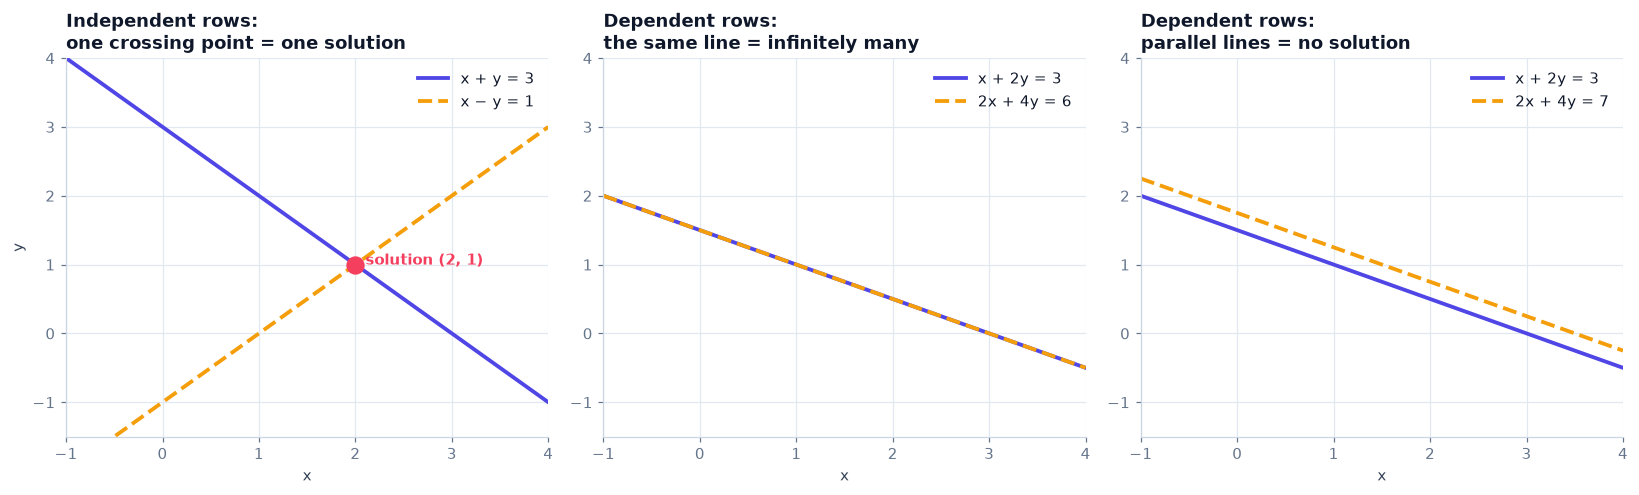

In [11]:
x = np.linspace(-1, 4, 200)    # x values to draw the lines over
# To draw a line such as  x + y = 3, rearrange it to  y = 3 - x

fig, axes = plt.subplots(1, 3, figsize=(15, 4.6))

# Panel 1: independent rows
axes[0].plot(x, 3 - x, color=BLUE, label="x + y = 3")
axes[0].plot(x, x - 1, "--", color=ORANGE, label="x − y = 1")
axes[0].plot(2, 1, "o", markersize=11, color=RED)              # the crossing point
axes[0].annotate("  solution (2, 1)", (2, 1), color=RED, fontweight="bold")
axes[0].set_title("Independent rows:\none crossing point = one solution")

# Panel 2: dependent rows (row 2 = 2 × row 1, and 6 = 2 × 3)
axes[1].plot(x, (3 - x) / 2, color=BLUE, label="x + 2y = 3")
axes[1].plot(x, (6 - 2 * x) / 4, "--", color=ORANGE, label="2x + 4y = 6")
axes[1].set_title("Dependent rows:\nthe same line = infinitely many")

# Panel 3: dependent rows, but 7 is not 2 × 3
axes[2].plot(x, (3 - x) / 2, color=BLUE, label="x + 2y = 3")
axes[2].plot(x, (7 - 2 * x) / 4, "--", color=ORANGE, label="2x + 4y = 7")
axes[2].set_title("Dependent rows:\nparallel lines = no solution")

for ax in axes:                 # same settings for all three panels
    ax.set_xlim(-1, 4)
    ax.set_ylim(-1.5, 4)
    ax.set_xlabel("x")
    ax.grid(True)
    ax.legend(loc="upper right")
axes[0].set_ylabel("y")
plt.show()

In the middle and right panels, the second equation is just the first one multiplied by 2 (apart from the right-hand side). The rows are **dependent**, so the two lines have the same slope. NumPy refuses to solve such a system:

In [12]:
A_dependent = np.array([[1, 2],
                        [2, 4]])
b = np.array([3, 6])

# Try to solve. If NumPy raises an error, print it instead of stopping the notebook.
try:
    np.linalg.solve(A_dependent, b)
except np.linalg.LinAlgError as error:
    print("❌ NumPy could not solve it:", error)

❌ NumPy could not solve it: Singular matrix


<div style="background-color:#F8FAFC; border:1px solid #E2E8F0; border-left:4px solid #7C3AED; border-radius:10px; color:#1E293B; padding:14px 20px; margin:14px 0;">

<span style="background-color:#EDE9FE; color:#5B21B6; font-size:11px; font-weight:700; letter-spacing:1.5px; padding:3px 10px; border-radius:999px;">ML CONNECTION</span>&nbsp;&nbsp;<b style="color:#0F172A; font-size:15px;">Why this matters for regression</b>

Fitting a linear regression means solving $X\boldsymbol\theta \approx \mathbf y$ for the coefficients $\boldsymbol\theta$, where each **column** of $X$ is a feature. If the features are dependent, **many different** $\boldsymbol\theta$ fit the data equally well. The model then cannot tell us what each feature's effect is.

</div>

### 4.2 A real example: the dummy-variable trap
This is the most common way dependent features sneak into a real model. We build it up in four steps.

**Step 1: turn a category into numbers.** We have data on people: **Age**, **Income** and **Gender**. A model needs numbers, so Gender is replaced by two 0/1 columns (this is called *one-hot encoding*):
`Male` = 1 if the person is male, else 0, and `Female` = 1 if female, else 0.

**Step 2: add the intercept column.** A linear model has a constant term $\theta_0$, the **intercept**:

$$
\text{prediction} = \theta_0 + \theta_1\,\text{Age} + \theta_2\,\text{Income} + \theta_3\,\text{Male} + \theta_4\,\text{Female}.
$$

To write this as a matrix product $X\boldsymbol\theta$, $\theta_0$ needs a column to multiply. We use a column of **ones**, so $\theta_0 \times 1 = \theta_0$ for every person. This column is called `Intercept`.

In [13]:
people = pd.DataFrame({
    "Intercept": [1, 1, 1, 1, 1, 1],                            # a column of ones
    "Age":       [25, 30, 35, 28, 42, 51],
    "Income":    [50000, 62000, 71000, 55000, 88000, 97000],
    "Male":      [1, 0, 1, 0, 0, 1],
}, index=["P1", "P2", "P3", "P4", "P5", "P6"])

people["Female"] = 1 - people["Male"]     # 1 if Male is 0, and 0 if Male is 1
people

,Intercept,Age,Income,Male,Female
P1,1,25,50000,1,0
P2,1,30,62000,0,1
P3,1,35,71000,1,0
P4,1,28,55000,0,1
P5,1,42,88000,0,1
P6,1,51,97000,1,0


**Step 3: spot the problem.** Every person is either male or female, so in every row `Male + Female` $= 1$. That is exactly the `Intercept` column, so one column can be built from two others. The rank confirms it:

In [14]:
# Is Male + Female the same as the Intercept column?
print("Male + Female:   ", (people["Male"] + people["Female"]).values)
print("Intercept column:", people["Intercept"].values, "  ← the same!")

# Rank with BOTH dummy columns
X_both = people[["Intercept", "Age", "Income", "Male", "Female"]].to_numpy()
print("\nWith Male AND Female:  rank", np.linalg.matrix_rank(X_both), "of", X_both.shape[1], "columns  ❌")

# Rank after dropping the Female column
X_dropped = people[["Intercept", "Age", "Income", "Male"]].to_numpy()
print("With Male only:        rank", np.linalg.matrix_rank(X_dropped), "of", X_dropped.shape[1], "columns  ✅")

Male + Female:    [1 1 1 1 1 1]
Intercept column: [1 1 1 1 1 1]   ← the same!

With Male AND Female:  rank 4 of 5 columns  ❌
With Male only:        rank 4 of 4 columns  ✅


**Step 4: see the consequence.** Take any set of coefficients $\boldsymbol\theta_a$. Now make a second set $\boldsymbol\theta_b$ by **adding 3 to the intercept** and **subtracting 3 from both** the Male and Female coefficients. Everybody has exactly one of `Male`/`Female` equal to 1, so the $+3$ and $-3$ always cancel:

In [15]:
# Two sets of coefficients, in the order: Intercept, Age, Income, Male, Female
theta_a = np.array([10, 2, 0.001, 5, 0])
theta_b = np.array([13, 2, 0.001, 2, -3])    # intercept +3, Male −3, Female −3

predictions_a = X_both @ theta_a             # one prediction per person
predictions_b = X_both @ theta_b

pd.DataFrame({"prediction with θ_a": predictions_a,
              "prediction with θ_b": predictions_b}, index=people.index)

,prediction with θ_a,prediction with θ_b
P1,115.0,115.0
P2,132.0,132.0
P3,156.0,156.0
P4,121.0,121.0
P5,182.0,182.0
P6,214.0,214.0


<div style="background-color:#F8FAFC; border:1px solid #E2E8F0; border-left:4px solid #E11D48; border-radius:10px; color:#1E293B; padding:14px 20px; margin:14px 0;">

<span style="background-color:#FFE4E6; color:#9F1239; font-size:11px; font-weight:700; letter-spacing:1.5px; padding:3px 10px; border-radius:999px;">PITFALL</span>&nbsp;&nbsp;<b style="color:#0F172A; font-size:15px;">The trap, and the fix</b>

The two coefficient sets give **identical predictions for every person**, so no amount of data can tell them apart. The "effect of being male" (5 in $\boldsymbol\theta_a$, 2 in $\boldsymbol\theta_b$) has no single answer.

**Fix:** drop one of the dummy columns, e.g. keep only `Male` or `Female`. In pandas: `pd.get_dummies(df, drop_first=True)`.

Note that `Male + Female = 1` only causes trouble **because the intercept column of ones is also there**. Without an intercept, those columns would be independent.

</div>

### 4.3 *Almost* dependent columns
Real data is rarely *exactly* dependent, but columns are often **nearly** dependent (e.g. a person's height in cm and in inches, with a little rounding noise). The matrix can still be solved, but the answer becomes **very sensitive**: a tiny change in the data gives a big change in the solution.

In [16]:
A_near = np.array([[1.0, 1.0],
                   [1.0, 1.001]])       # the two columns are almost identical

b     = np.array([2.0, 2.001])
b_new = np.array([2.0, 2.000])          # change one number by just 0.001

x     = np.linalg.solve(A_near, b)
x_new = np.linalg.solve(A_near, b_new)

print("b     =", b,     "  →  solution x =", x)
print("b_new =", b_new, "  →  solution x =", x_new)

change_in_b = np.linalg.norm(b_new - b)     # norm = length of the change
change_in_x = np.linalg.norm(x_new - x)
print(f"\nThe data changed by {change_in_b:.3f}, but the solution moved by {change_in_x:.2f}!")
print(f"Condition number of A: {np.linalg.cond(A_near):.0f}")

b     = [2.    2.001]   →  solution x = [1. 1.]
b_new = [2. 2.]   →  solution x = [2. 0.]

The data changed by 0.001, but the solution moved by 1.41!
Condition number of A: 4002


#### Why does this happen? Picture it with lines
Remember from 4.1 that each equation is a **line**, and the solution is the point where the lines **cross**. Changing $\mathbf b$ slides a line sideways without changing its slope.

When the columns are nearly dependent, the two lines are **nearly parallel**. In the example above they are so close you couldn't tell them apart on a plot, so below we use a less extreme pair to show the idea. Both panels get **exactly the same small nudge** to line 2 (its right-hand side goes up by 0.3).

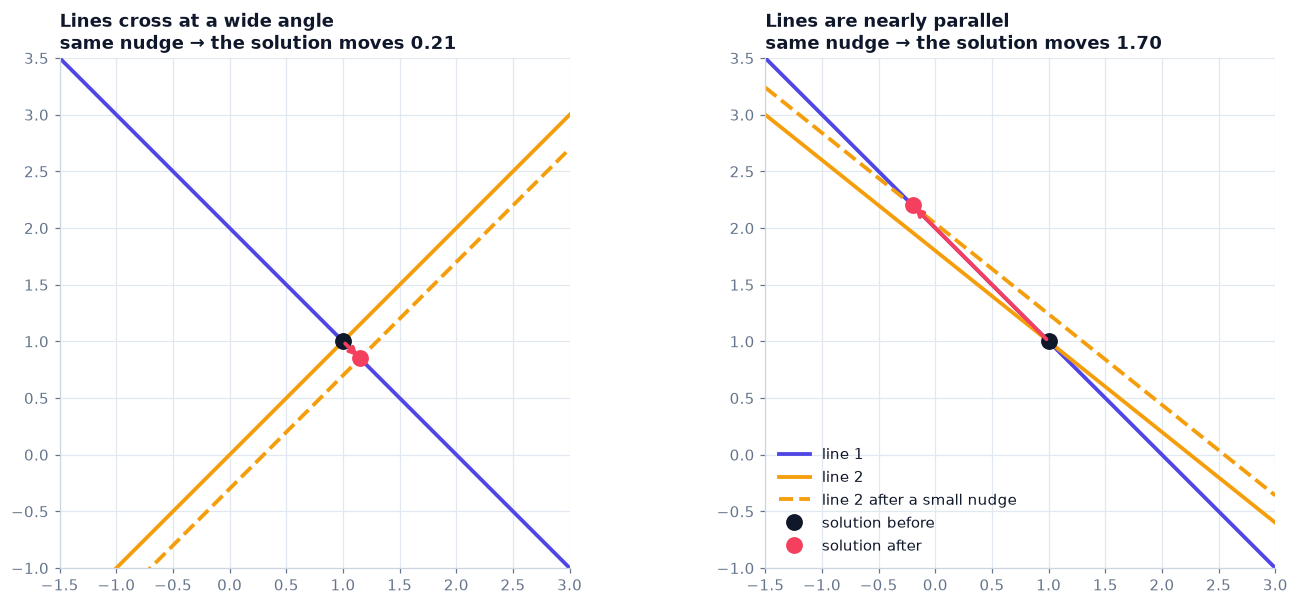

In [17]:
def plot_nudge(ax, a, c, d, d_new, title):
    """Draw line 1 (x + y = 2) and line 2 (a·x + c·y = d), then nudge line 2 to a·x + c·y = d_new."""
    x = np.linspace(-1.5, 3, 200)

    # Where the lines cross, before and after the nudge
    A = np.array([[1, 1],
                  [a, c]])
    before = np.linalg.solve(A, [2, d])
    after  = np.linalg.solve(A, [2, d_new])

    ax.plot(x, 2 - x, color=BLUE, label="line 1")
    ax.plot(x, (d - a * x) / c, color=ORANGE, label="line 2")
    ax.plot(x, (d_new - a * x) / c, "--", color=ORANGE, label="line 2 after a small nudge")
    ax.plot(before[0], before[1], "o", markersize=10, color=DARK, label="solution before")
    ax.plot(after[0], after[1], "o", markersize=10, color=RED, label="solution after")
    ax.annotate("", xy=after, xytext=before, arrowprops=dict(arrowstyle="->", lw=2.5, color=RED))

    distance = np.linalg.norm(after - before)
    ax.set_title(f"{title}\nsame nudge → the solution moves {distance:.2f}")
    ax.set_xlim(-1.5, 3)
    ax.set_ylim(-1, 3.5)
    ax.set_aspect("equal")
    ax.grid(True)


fig, axes = plt.subplots(1, 2, figsize=(13, 5.6))
plot_nudge(axes[0], a=1, c=-1,   d=0.00, d_new=0.30, title="Lines cross at a wide angle")
plot_nudge(axes[1], a=1, c=1.25, d=2.25, d_new=2.55, title="Lines are nearly parallel")
axes[1].legend(loc="lower left")
plt.show()

<div style="background-color:#F8FAFC; border:1px solid #E2E8F0; border-left:4px solid #0D9488; border-radius:10px; color:#1E293B; padding:14px 20px; margin:14px 0;">

<span style="background-color:#CCFBF1; color:#115E59; font-size:11px; font-weight:700; letter-spacing:1.5px; padding:3px 10px; border-radius:999px;">INTUITION</span>&nbsp;&nbsp;<b style="color:#0F172A; font-size:15px;">Why nearly parallel means unstable</b>

Nearly parallel lines stay **close to each other over a long stretch**. Slide one of them sideways by a small amount, and the place where they meet **slides a long way along that stretch**.

The smaller the angle between the lines, the further the crossing moves. At an angle of zero (exactly parallel, i.e. exactly dependent) there is no crossing at all, as we saw in 4.1.

</div>

#### The same story in terms of features
Solving $A\mathbf x = \mathbf b$ means finding how much of each **column** (feature) we need to build $\mathbf b$:

$$
x_1 \begin{bmatrix} 1 \\ 1 \end{bmatrix} + x_2 \begin{bmatrix} 1 \\ 1.001 \end{bmatrix} = \mathbf b .
$$

The two columns are almost the same vector. The only direction in which they differ is their **difference**, $(0,\ 0.001)$, which is tiny.

In our example, $\mathbf b$ changed by exactly $(0,\ -0.001)$: minus that difference. The only way to build this change is **plus one** of column 1 and **minus one** of column 2. So the solution must change by $(+1,\ -1)$, which is exactly the jump from $(1, 1)$ to $(2, 0)$ we saw above.

A change of $0.001$ in the data forced a change of $1$ in each coefficient, **1000 times larger**, because the two features differ by only $0.001$. In a regression, the "small change in $\mathbf b$" is **noise in the data**, so nearly copied features make the coefficients swing wildly. Section 4.4 shows exactly that.

<div style="background-color:#F8FAFC; border:1px solid #E2E8F0; border-left:4px solid #4F46E5; border-radius:10px; color:#1E293B; padding:14px 20px; margin:14px 0;">

<span style="background-color:#EEF2FF; color:#3730A3; font-size:11px; font-weight:700; letter-spacing:1.5px; padding:3px 10px; border-radius:999px;">DEFINITION</span>&nbsp;&nbsp;<b style="color:#0F172A; font-size:15px;">Condition number κ</b>

The **condition number** $\kappa(A)$ measures how much a matrix can **amplify small errors** in the data.
- $\kappa$ close to 1: safe.
- $\kappa$ very large (like the 4000 above): small errors can become huge.
- $\kappa = \infty$: exactly dependent columns.

NumPy computes it with `np.linalg.cond(A)`.

</div>

### 4.4 What this does to a regression model
We generate **500 small datasets** from the same rule $y = 3x_1 + 2x_2 + \text{noise}$, fit a linear regression to each one, and plot the two fitted coefficients $(\hat\theta_1, \hat\theta_2)$. The true answer is $(3, 2)$ (the star).
- **Left:** $x_1$ and $x_2$ are unrelated features.
- **Right:** $x_2$ is almost a copy of $x_1$.

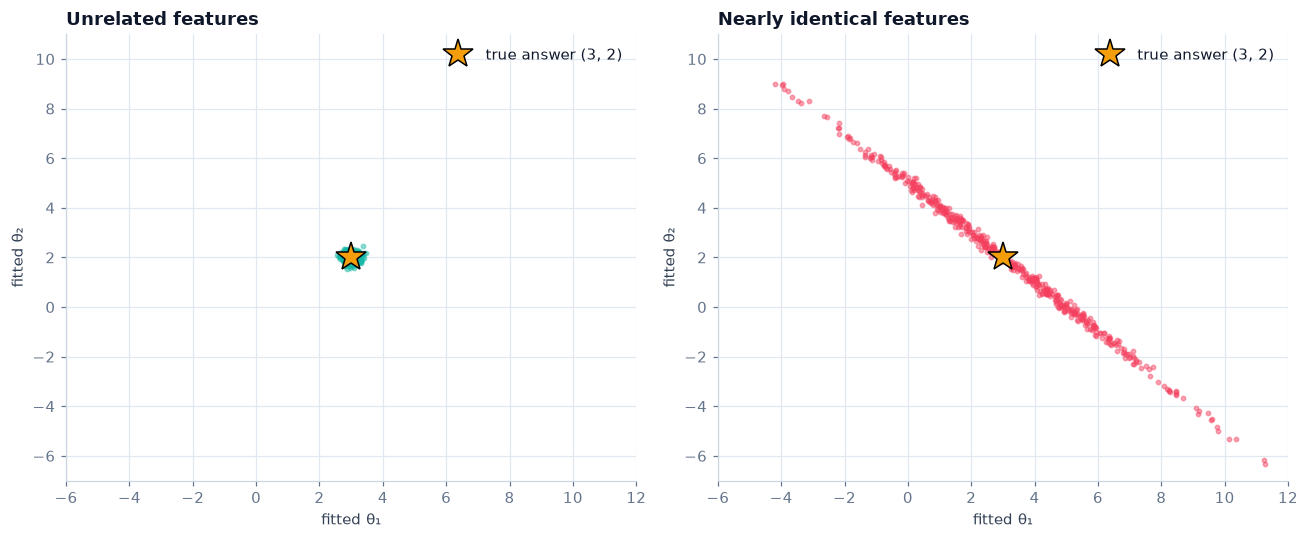

In [18]:
def fit_many_datasets(nearly_copied):
    """Make 500 small datasets from y = 3*x1 + 2*x2 + noise, and fit a regression to each.
    Returns an array with one row (theta1, theta2) per dataset."""
    rng = np.random.default_rng(1)
    all_thetas = []

    for i in range(500):
        x1 = rng.normal(size=50)                        # 50 random values
        if nearly_copied:
            x2 = x1 + 0.05 * rng.normal(size=50)        # x2 = x1 plus a tiny bit of noise
        else:
            x2 = rng.normal(size=50)                    # x2 has nothing to do with x1
        y = 3 * x1 + 2 * x2 + rng.normal(size=50)       # the true rule, plus noise

        X = np.column_stack([x1, x2])                   # feature matrix: one column per feature
        thetas = np.linalg.lstsq(X, y, rcond=None)[0]    # least-squares fit ([0] = the coefficients)
        all_thetas.append(thetas)

    return np.array(all_thetas)


thetas_unrelated = fit_many_datasets(nearly_copied=False)
thetas_copied = fit_many_datasets(nearly_copied=True)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
axes[0].scatter(thetas_unrelated[:, 0], thetas_unrelated[:, 1], s=8, alpha=0.45, color=TEAL)
axes[0].set_title("Unrelated features")
axes[1].scatter(thetas_copied[:, 0], thetas_copied[:, 1], s=8, alpha=0.45, color=RED)
axes[1].set_title("Nearly identical features")

for ax in axes:
    ax.plot(3, 2, "*", markersize=20, color=ORANGE, markeredgecolor="black", label="true answer (3, 2)")
    ax.set_xlim(-6, 12)
    ax.set_ylim(-7, 11)
    ax.set_xlabel("fitted θ₁")
    ax.set_ylabel("fitted θ₂")
    ax.grid(True)
    ax.legend(loc="upper right")
plt.show()

<div style="background-color:#F8FAFC; border:1px solid #E2E8F0; border-left:4px solid #0D9488; border-radius:10px; color:#1E293B; padding:14px 20px; margin:14px 0;">

<span style="background-color:#CCFBF1; color:#115E59; font-size:11px; font-weight:700; letter-spacing:1.5px; padding:3px 10px; border-radius:999px;">INTUITION</span>&nbsp;&nbsp;<b style="color:#0F172A; font-size:15px;">What this tells us</b>

With **unrelated** features, every dataset gives nearly the right answer (tight cluster). With **nearly identical** features, the model can only learn that $\theta_1 + \theta_2 \approx 5$. It cannot tell how to split that total between the two features, so the estimates spread along a line, sometimes even with the wrong sign.

</div>

<a id="sec5"></a>

<div style="margin-top:28px; font-size:12px; font-weight:700; letter-spacing:3px; color:#4F46E5;">SECTION 05</div>

## The Determinant

<div style="color:#64748B; font-size:15px;">A single number that tells us whether a matrix squashes space flat.</div>

<hr style="border:none; height:4px; width:56px; background-color:#4F46E5; border-radius:2px; margin:12px 0 6px 0;">

<div style="background-color:#F8FAFC; border:1px solid #E2E8F0; border-left:4px solid #4F46E5; border-radius:10px; color:#1E293B; padding:14px 20px; margin:14px 0;">

<span style="background-color:#EEF2FF; color:#3730A3; font-size:11px; font-weight:700; letter-spacing:1.5px; padding:3px 10px; border-radius:999px;">DEFINITION</span>&nbsp;&nbsp;<b style="color:#0F172A; font-size:15px;">What the determinant measures</b>

A $2\times2$ matrix turns the unit square into a parallelogram whose sides are the matrix's **columns**. The **determinant** tells us its area:

$$
\lvert \det A \rvert = \text{area of the parallelogram}.
$$

If $\det A = 0$, the parallelogram is **flattened into a line**: the columns are dependent and the matrix cannot be inverted.

</div>

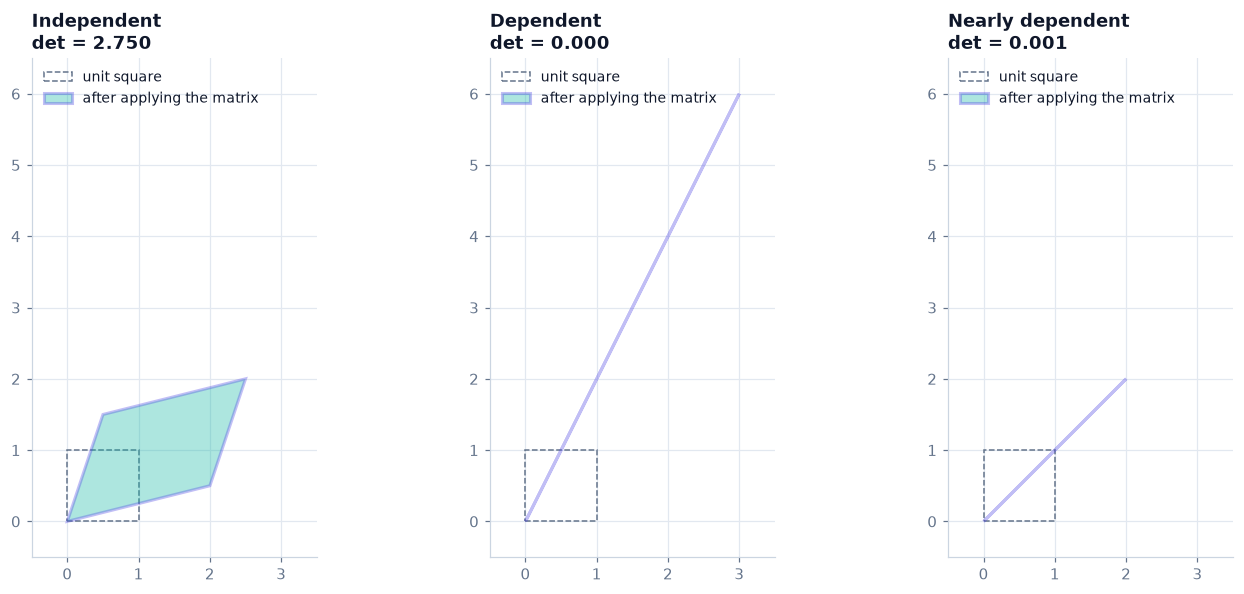

In [19]:
from matplotlib.patches import Polygon

# Corners of the unit square, one corner per column: (0,0), (1,0), (1,1), (0,1)
square = np.array([[0, 1, 1, 0],
                   [0, 0, 1, 1]])

def draw_square_and_image(ax, matrix, title):
    """Draw the unit square, and the shape it becomes after multiplying by the matrix."""
    new_corners = matrix @ square                       # apply the matrix to every corner
    ax.add_patch(Polygon(square.T, fill=False, linestyle="--", edgecolor=GREY, label="unit square"))
    ax.add_patch(Polygon(new_corners.T, alpha=0.35, facecolor=TEAL, edgecolor=BLUE,
                         linewidth=2, label="after applying the matrix"))
    ax.set_title(f"{title}\ndet = {np.linalg.det(matrix):.3f}")
    ax.set_xlim(-0.5, 3.5)
    ax.set_ylim(-0.5, 6.5)
    ax.set_aspect("equal")
    ax.grid(True)
    ax.legend(loc="upper left", fontsize=9)


fig, axes = plt.subplots(1, 3, figsize=(13, 5.5))
draw_square_and_image(axes[0], np.array([[2.0, 0.5], [0.5, 1.5]]),   "Independent")
draw_square_and_image(axes[1], np.array([[1.0, 2.0], [2.0, 4.0]]),   "Dependent")
draw_square_and_image(axes[2], np.array([[1.0, 1.0], [1.0, 1.001]]), "Nearly dependent")
plt.show()

<div style="background-color:#F8FAFC; border:1px solid #E2E8F0; border-left:4px solid #E11D48; border-radius:10px; color:#1E293B; padding:14px 20px; margin:14px 0;">

<span style="background-color:#FFE4E6; color:#9F1239; font-size:11px; font-weight:700; letter-spacing:1.5px; padding:3px 10px; border-radius:999px;">PITFALL</span>&nbsp;&nbsp;<b style="color:#0F172A; font-size:15px;">Careful with "small" determinants</b>

The determinant depends on the **units** of the data. For example, the matrix $0.1 \times I$ (size $10\times10$) has $\det = 10^{-10}$, yet it is perfectly well behaved: it just shrinks everything evenly. To judge whether a matrix is *nearly* dependent, use the **rank** and the **condition number** κ (Section 4.3) instead.

</div>

<a id="sec6"></a>

<div style="margin-top:28px; font-size:12px; font-weight:700; letter-spacing:3px; color:#4F46E5;">SECTION 06</div>

## Putting It Together: Linear Regression

<div style="color:#64748B; font-size:15px;">Fitting a straight line uses everything from this tutorial.</div>

<hr style="border:none; height:4px; width:56px; background-color:#4F46E5; border-radius:2px; margin:12px 0 6px 0;">

We want to predict a house's **price** from its **size** with a straight line: $\text{price} \approx \theta_0 + \theta_1 \cdot \text{size}$.

**The design matrix.** As in Section 4.2, we put a column of ones (for the intercept $\theta_0$) next to the sizes. Then all predictions at once are $X\boldsymbol\theta$:

$$
X = \begin{bmatrix} 1 & \text{size}_1 \\ \vdots & \vdots \\ 1 & \text{size}_N \end{bmatrix},
\qquad
\boldsymbol\theta = \begin{bmatrix} \theta_0 \\ \theta_1 \end{bmatrix}.
$$

**The best fit.** As in Section 4.4, we use `np.linalg.lstsq`. It finds the coefficients $\hat{\boldsymbol\theta}$ with the **smallest squared error** between the predictions $X\hat{\boldsymbol\theta}$ and the prices $\mathbf y$. We'll see how it does this later in the course.

This best fit is unique **only if the columns of $X$ are independent**, which is exactly why Sections 2 to 5 matter.

Intercept θ₀ = 3.62
Slope     θ₁ = 0.1456  →  each extra square foot adds about £146


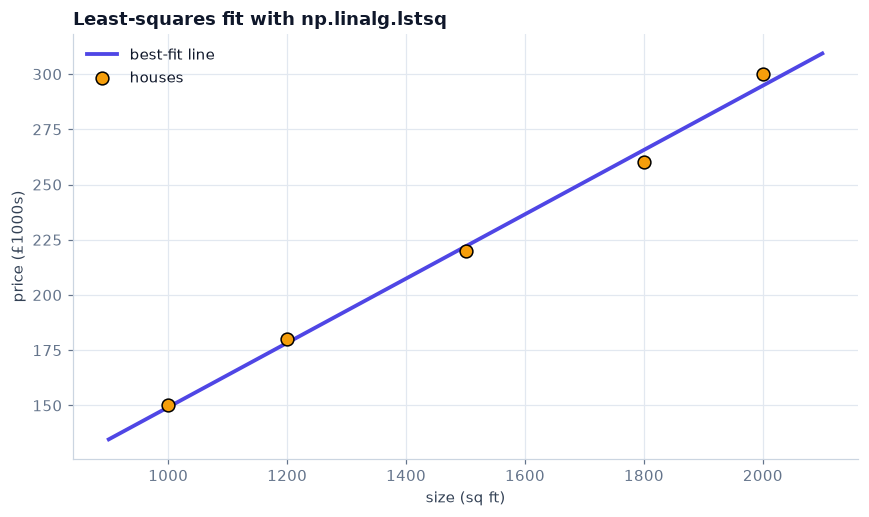

In [20]:
sizes  = np.array([1000, 1200, 1500, 1800, 2000])    # square feet
prices = np.array([ 150,  180,  220,  260,  300])    # £1000s

# Design matrix: a column of ones (for the intercept) next to the sizes
ones = np.ones(len(sizes))
X = np.column_stack([ones, sizes])

# Least-squares fit: the coefficients with the smallest squared error ([0] = the coefficients)
theta = np.linalg.lstsq(X, prices, rcond=None)[0]
intercept = theta[0]
slope = theta[1]

print(f"Intercept θ₀ = {intercept:.2f}")
print(f"Slope     θ₁ = {slope:.4f}  →  each extra square foot adds about £{1000 * slope:.0f}")

# Plot the houses and the best-fit line
line_x = np.linspace(900, 2100, 100)
line_y = intercept + slope * line_x

fig, ax = plt.subplots(figsize=(8, 4.8))
ax.plot(line_x, line_y, color=BLUE, label="best-fit line")
ax.scatter(sizes, prices, s=70, color=ORANGE, edgecolor="black", zorder=3, label="houses")
ax.set_xlabel("size (sq ft)")
ax.set_ylabel("price (£1000s)")
ax.set_title("Least-squares fit with np.linalg.lstsq")
ax.grid(True)
ax.legend(loc="upper left")
plt.show()

<div style="background-color:#F8FAFC; border:1px solid #E2E8F0; border-left:4px solid #D97706; border-radius:10px; color:#1E293B; padding:14px 20px; margin:14px 0;">

<span style="background-color:#FEF3C7; color:#92400E; font-size:11px; font-weight:700; letter-spacing:1.5px; padding:3px 10px; border-radius:999px;">EXERCISE</span>&nbsp;&nbsp;<b style="color:#0F172A; font-size:15px;">Exercise 3</b>

Add a third column to `X` containing the size in **square metres** (`sizes * 0.0929`). What is the rank of the new matrix? Explain why it is lower than the number of columns.

<details>
<summary><b>Show solution ▸</b></summary>

```python
X3 = np.column_stack([X, sizes * 0.0929])
np.linalg.matrix_rank(X3)       # 2, but there are 3 columns
```
Size in m² is just size in sq ft multiplied by a constant, so the new column adds **no new information**: the columns are dependent and the rank stays at 2. Many different $\boldsymbol\theta$ then fit the data equally well, so there is no unique best fit. This is the same problem as the dummy-variable trap.

</details>

</div>

In [21]:
# ✏️ Exercise 3: your code here

<a id="sec7"></a>

<div style="margin-top:28px; font-size:12px; font-weight:700; letter-spacing:3px; color:#4F46E5;">SECTION 07</div>

## Summary

<div style="color:#64748B; font-size:15px;">What to remember, and a quick check for any feature matrix.</div>

<hr style="border:none; height:4px; width:56px; background-color:#4F46E5; border-radius:2px; margin:12px 0 6px 0;">

| | ✅ **Independent columns** | ❌ **Dependent columns** | ⚠️ **Nearly dependent** |
|:--|:--|:--|:--|
| **Rank** | $=$ number of columns | $<$ number of columns | $=$ number of columns |
| **Condition number κ** | moderate | $\infty$ | very large |
| **Solving $X\boldsymbol\theta = \mathbf y$** | one best answer | many equally good answers | one answer, but very sensitive |
| **In a model** | reliable coefficients | coefficients have no meaning | coefficients jump around |

The function below runs these checks for you. Try it on your own matrices.

In [22]:
def check_features(X, name):
    """Print the rank and condition number of a feature matrix, with a verdict."""
    X = np.array(X, dtype=float)
    rank = np.linalg.matrix_rank(X)
    num_columns = X.shape[1]
    kappa = np.linalg.cond(X)

    if rank < num_columns:
        verdict = "❌ dependent: some columns are redundant"
    elif kappa > 1000:
        verdict = "⚠️ independent, but nearly dependent (large κ)"
    else:
        verdict = "✅ independent"

    print(name)
    print(f"    rank {rank} of {num_columns},  κ = {kappa:.3g}  →  {verdict}")


check_features(examples["4×3, independent columns"],     "4×3 independent example")
check_features(examples["4×3, col 3 = 2·col 1 + col 2"], "4×3 dependent example")
check_features(X_both,                                   "Dummy trap (Male and Female)")
check_features(A_near,                                   "Nearly dependent 2×2")

4×3 independent example
    rank 3 of 3,  κ = 3.2  →  ✅ independent
4×3 dependent example
    rank 2 of 3,  κ = 3.3e+16  →  ❌ dependent: some columns are redundant
Dummy trap (Male and Female)
    rank 4 of 5,  κ = 4.96e+20  →  ❌ dependent: some columns are redundant
Nearly dependent 2×2
    rank 2 of 2,  κ = 4e+03  →  ⚠️ independent, but nearly dependent (large κ)


<div style="background-color:#F8FAFC; border:1px solid #E2E8F0; border-left:4px solid #4F46E5; border-radius:10px; color:#1E293B; padding:14px 20px; margin:14px 0;">

<span style="background-color:#EEF2FF; color:#3730A3; font-size:11px; font-weight:700; letter-spacing:1.5px; padding:3px 10px; border-radius:999px;">SUMMARY</span>&nbsp;&nbsp;<b style="color:#0F172A; font-size:15px;">Key takeaways</b>

1. The **transpose** swaps rows and columns. Transpose + flip = **rotation**.
2. Vectors are **independent** if none can be built from the others. Each one adds a new direction.
3. The **rank** counts the independent columns of a matrix.
4. **Dependent features** (like the dummy-variable trap) mean a model has **no unique answer**. Fix it by removing the redundant column.
5. **Nearly dependent** features give a large **condition number** and unstable coefficients.
6. Before trusting a model's coefficients, **check the rank and condition number of your feature matrix**.

</div>

<div style="background-color:#1E1B4B; background-image:linear-gradient(135deg, #0F172A 0%, #312E81 100%); color:#FFFFFF; border-radius:16px; padding:24px 30px;">
<div style="font-size:12px; letter-spacing:3px; color:#A5B4FC; font-weight:700;">GOING FURTHER</div>
<div style="color:#E2E8F0; margin-top:8px; font-size:15px;">
Load a real dataset (e.g. <code style="color:#FFFFFF; background-color:#1E293B;">sklearn.datasets.fetch_california_housing</code>), build its feature matrix, and run <code style="color:#FFFFFF; background-color:#1E293B;">check_features</code> on it. Are any features nearly dependent?
</div>
<div style="font-size:12px; color:#94A3B8; margin-top:16px;">ELEC70144 · Mathematics for Machine Learning · Imperial College London · 2026–2027</div>
</div>